In [18]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# 1 IMPORT LIBRARIES

In [19]:
import pandas as pd
import numpy as np
# Plot Cumulative Returns
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE
from imblearn.combine import SMOTEENN
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import make_scorer, recall_score

# INITIALIZE DATA AND CREATE VIX STRUCTURE FEATURES

In [20]:
data = pd.read_excel('data/ASSURANCE VIE.xlsx', sheet_name='VIXHISTORIQUEMODEL')
data.rename(columns={'VIX': 'VIX1M'},inplace=True)

# Format the 'Date' column to show only the date (YYYY-MM-DD)
data['Date'] = data['Date'].dt.strftime('%Y-%m-%d')

# Set 'Date' as the index
data = data.set_index('Date')
# Ensure the index is converted to datetime format
data.index = pd.to_datetime(data.index, errors='coerce')
data = data.sort_index()
data.dropna(inplace=True)

In [21]:
data

,SPX,VIX1M,VIX3M,VIX6M,VIX1Y
Date,,,,,
2018-06-08,2779.03,12.18,14.60,16.13,17.23
2018-06-11,2782.00,12.35,14.55,16.12,17.17
2018-06-12,2786.85,12.34,14.59,16.17,17.23
2018-06-13,2775.63,12.94,14.92,16.43,17.44
2018-06-14,2782.49,12.12,14.40,16.09,17.31
...,...,...,...,...,...
2024-10-09,5792.04,20.86,20.91,21.85,22.55
2024-10-10,5780.05,20.93,21.02,21.96,22.54
2024-10-11,5815.03,20.46,20.77,21.76,22.47


# 3 CREATE CRASH TARGET METRIC

In [13]:
alpha = -0.05  # Set crash return threshold

In [25]:
# BASIC 1 DAY RETURN TARGET
# Calculate the forward return (T+1) / T - 1
data['SPX_Fwd_Return'] = data['SPX'].shift(-1) / data['SPX'] - 1

# Create the target column based on the condition
data['Target'] = (data['SPX_Fwd_Return'] < alpha).astype(int)

In [8]:
# CREATE A MORE SOPHISTICATED TARGET: Has there been a crash in the next month window
# Initialize the crash_1M column with 0s
data['crash_1M'] = 0
data['crash_date'] = 0
# Initialize a new DataFrame to store the crash flag for all dates
crash_dates_df = pd.DataFrame(data.index, columns=['Date'])
crash_dates_df['crash_flag'] = 0  # Start with all zeros
crash_dates_df.set_index('Date')
# Loop over each date in the DataFrame
for current_date in data.index:
    # Define the 1-month window
    end_date = current_date + pd.DateOffset(days=30)
    
    # Skip if the window extends beyond available data
    if end_date > data.index[-1]:
        continue
    
    # Extract SPX values within the 1-month window
    window_data = data.loc[current_date:end_date, 'SPX']
    
    # Check all possible returns within the window to see if any meet the crash threshold
    crash_flag = False
    for i in range(len(window_data)):
        for j in range(i + 1, len(window_data)):
            # Calculate the return between SPX[i] and SPX[j]
            return_within_window = (window_data.iloc[j] / window_data.iloc[i]) - 1
            if return_within_window < alpha:
                crash_flag = True
                crash_start_date=window_data.index[i]
                crash_end_date = window_data.index[j]
                break
        if crash_flag:
            break

    # If a crash is detected, set crash_1M to 1 for all dates in the 1-month window
    if crash_flag:
        data.loc[current_date, 'crash_1M'] = 1
        data.loc[current_date, 'crash_start_date'] = crash_start_date
        data.loc[current_date, 'crash_end_date'] = crash_end_date
        # Update the crash_flag in crash_dates_df for each date in the 1-month window
        crash_dates_df.loc[crash_dates_df['Date'] == crash_start_date, 'crash_flag'] = 1
# Display the DataFrame to check the crash_1M target column
crash_dates_df.set_index('Date',inplace=True)

In [22]:
# CRASH V2
CRASH_FLAG=-0.05 # return of S&P
TIME_WINDOW=10 # 2 WEEKS

# Initialize the crash_1M column with 0s
data['crash_Flag'] = 0
data['crash_start_date'] = 0
data['crash_end_date'] = 0


# Initialize a new DataFrame to store the crash flag for all dates
crash_dates_df = pd.DataFrame(data.index, columns=['Date'])
crash_dates_df['crash_flag'] = 0  # Start with all zeros
crash_dates_df.set_index('Date')
# Loop over each date in the DataFrame
for current_date in data.index:
    # Define the 1-month window
    end_date = current_date + pd.DateOffset(days=TIME_WINDOW)
    
    # Skip if the window extends beyond available data
    if end_date > data.index[-1]:
        continue
    
    # Extract SPX values within the 1-month window
    window_data = data.loc[current_date:end_date, 'SPX']
    initial_SPX= data.loc[current_date, 'SPX']
    # Check all possible returns within the window to see if any meet the crash threshold
    crash_flag = False
    for i in range(len(window_data)):
            # Calculate the return between SPX[i] and SPX[j]
        return_within_window = (window_data.iloc[i] / initial_SPX) - 1
        if return_within_window < CRASH_FLAG:
            crash_flag = True
            crash_start_date=current_date
            crash_end_date = window_data.index[i]
            break
        if crash_flag:
            break

    # If a crash is detected, set crash_1M to 1 for all dates in the 1-month window
    if crash_flag:
        data.loc[current_date, 'crash_Flag'] = 1
        data.loc[current_date, 'crash_start_date'] = crash_start_date
        data.loc[current_date, 'crash_end_date'] = crash_end_date
        # Update the crash_flag in crash_dates_df for each date in the 1-month window
        crash_dates_df.loc[crash_dates_df['Date'] == crash_start_date, 'crash_flag'] = 1
# Display the DataFrame to check the crash_1M target column
crash_dates_df.set_index('Date',inplace=True)

/var/folders/2g/jybkt1rx3x731rqm3lckb_j80000gn/T/ipykernel_70220/2089451370.py:43: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '2018-10-01 00:00:00' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  data.loc[current_date, 'crash_start_date'] = crash_start_date
/var/folders/2g/jybkt1rx3x731rqm3lckb_j80000gn/T/ipykernel_70220/2089451370.py:44: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '2018-10-11 00:00:00' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  data.loc[current_date, 'crash_end_date'] = crash_end_date


In [26]:
data[data['crash_Flag'] == 1]

,SPX,VIX1M,VIX3M,VIX6M,VIX1Y,crash_Flag,crash_start_date,crash_end_date,SPX_Fwd_Return,Target
Date,,,,,,,,,,
2018-10-01,2924.59,12.00,14.74,15.95,17.20,1,2018-10-01 00:00:00,2018-10-11 00:00:00,-0.000397,0
2018-10-02,2923.43,12.05,14.84,16.03,17.22,1,2018-10-02 00:00:00,2018-10-11 00:00:00,0.000711,0
2018-10-03,2925.51,11.61,14.68,15.96,17.17,1,2018-10-03 00:00:00,2018-10-11 00:00:00,-0.008170,0
2018-10-04,2901.61,14.22,15.84,16.70,17.61,1,2018-10-04 00:00:00,2018-10-11 00:00:00,-0.005528,0
2018-10-05,2885.57,14.82,16.25,17.14,17.97,1,2018-10-05 00:00:00,2018-10-11 00:00:00,-0.000395,0
...,...,...,...,...,...,...,...,...,...,...
2022-12-13,4019.65,22.55,24.29,26.26,27.85,1,2022-12-13 00:00:00,2022-12-19 00:00:00,-0.006053,0
2023-10-16,4373.63,17.21,18.79,20.64,22.62,1,2023-10-16 00:00:00,2023-10-26 00:00:00,-0.000098,0
2023-10-17,4373.20,17.88,19.26,21.06,22.93,1,2023-10-17 00:00:00,2023-10-26 00:00:00,-0.013400,0


In [28]:
(len(data[data['crash_Flag'] == 1])/len(data))*100

6.089139987445072

In [29]:
data.to_excel('./data/crash_analysis_new.xlsx')

In [99]:
 flagged_crashes=crash_dates_df[crash_dates_df['crash_flag'] == 1]

In [100]:
flagged_crashes

,crash_flag
Date,
2018-09-11,1
2018-09-12,1
2018-09-13,1
2018-09-14,1
2018-09-17,1
...,...
2024-07-19,1
2024-07-22,1
2024-07-23,1


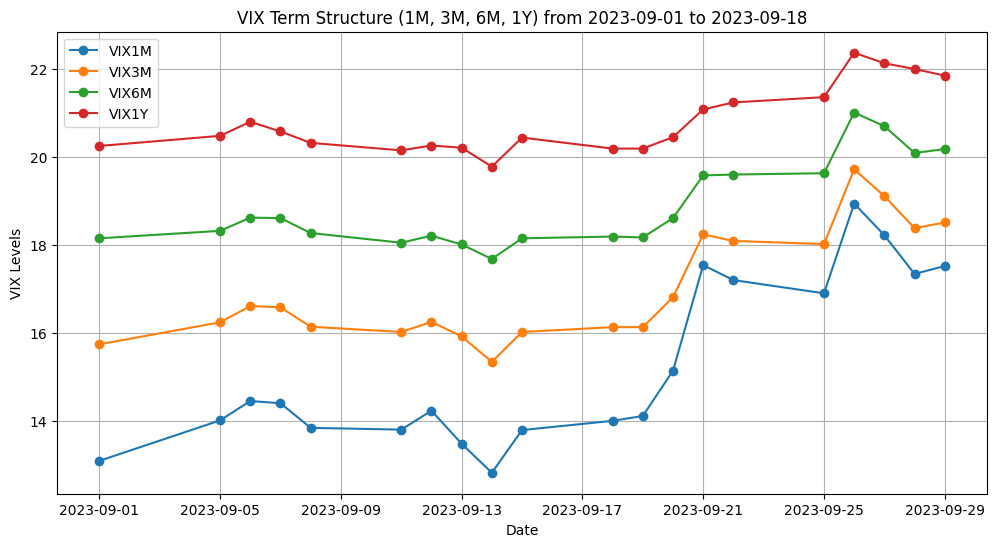

In [101]:
date_range_df = data.loc['2023-09-01':'2023-09-30']  # Filter by date range

# Plot VIX columns on the same graph
plt.figure(figsize=(12, 6))
plt.plot(date_range_df.index, date_range_df['VIX1M'], label='VIX1M', marker='o')
plt.plot(date_range_df.index, date_range_df['VIX3M'], label='VIX3M', marker='o')
plt.plot(date_range_df.index, date_range_df['VIX6M'], label='VIX6M', marker='o')
plt.plot(date_range_df.index, date_range_df['VIX1Y'], label='VIX1Y', marker='o')

# Add titles and labels
plt.title("VIX Term Structure (1M, 3M, 6M, 1Y) from 2023-09-01 to 2023-09-18")
plt.xlabel("Date")
plt.ylabel("VIX Levels")
plt.legend()
plt.grid()
plt.show()


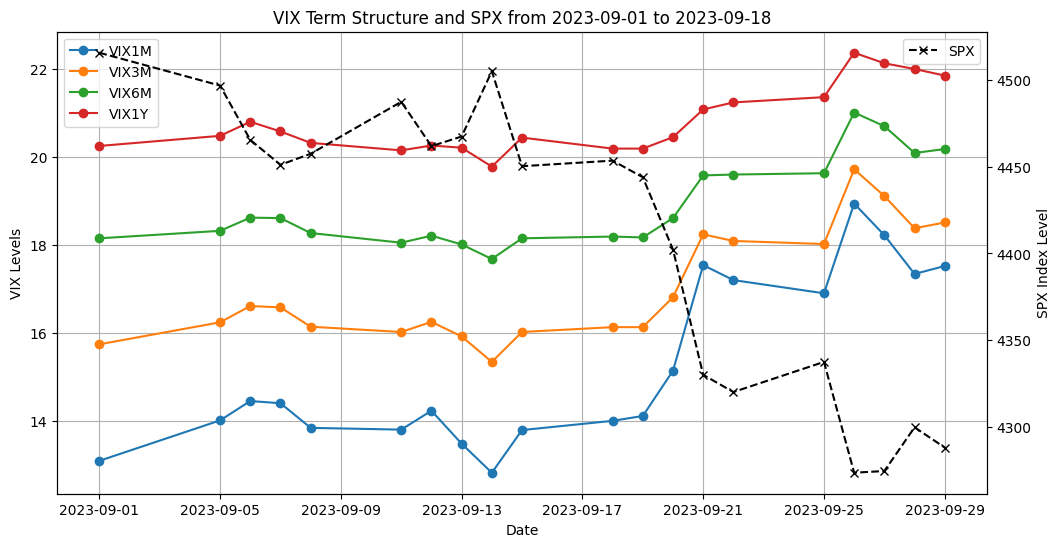

In [11]:
# Create the main plot for VIX columns
fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot VIX columns
ax1.plot(date_range_df.index, date_range_df['VIX1M'], label='VIX1M', marker='o')
ax1.plot(date_range_df.index, date_range_df['VIX3M'], label='VIX3M', marker='o')
ax1.plot(date_range_df.index, date_range_df['VIX6M'], label='VIX6M', marker='o')
ax1.plot(date_range_df.index, date_range_df['VIX1Y'], label='VIX1Y', marker='o')

# Label for the VIX axis
ax1.set_ylabel("VIX Levels")
ax1.set_xlabel("Date")
ax1.legend(loc="upper left")
ax1.grid()

# Create a second y-axis for SPX
ax2 = ax1.twinx()
ax2.plot(date_range_df.index, date_range_df['SPX'], label='SPX', color='black', linestyle='--', marker='x')
ax2.set_ylabel("SPX Index Level")
ax2.legend(loc="upper right")

# Add title
plt.title("VIX Term Structure and SPX from 2023-09-01 to 2023-09-18")

plt.show()


In [12]:
data[data['crash_1M'] == 1].tail(50)

,SPX,VIX1M,VIX3M,VIX6M,VIX1Y,SPX_Fwd_Return,Target,crash_1M
Date,,,,,,,,
2023-09-11,4487.46,13.80,16.02,18.05,20.15,-0.005696,0,1
2023-09-12,4461.90,14.23,16.25,18.21,20.26,0.001242,0,1
2023-09-13,4467.44,13.48,15.92,18.01,20.21,0.008430,0,1
2023-09-14,4505.10,12.82,15.34,17.68,19.78,-0.012160,0,1
2023-09-15,4450.32,13.79,16.02,18.15,20.44,0.000721,0,1
2023-09-18,4453.53,14.00,16.13,18.19,20.19,-0.002151,0,1
2023-09-26,4273.53,18.94,19.72,21.01,22.37,0.000229,0,1
2023-09-27,4274.51,18.22,19.11,20.70,22.13,0.005893,0,1
2023-09-28,4299.70,17.34,18.38,20.09,22.00,-0.002709,0,1


In [13]:
# Show the probability of occurrence
proba_all = round(100 * data['crash_1M'].value_counts().get(1, 0) / len(data), 2)
print(f"Number of crash occurrences across all period: {proba_all}%")



Number of crash occurrences across all period: 28.19%


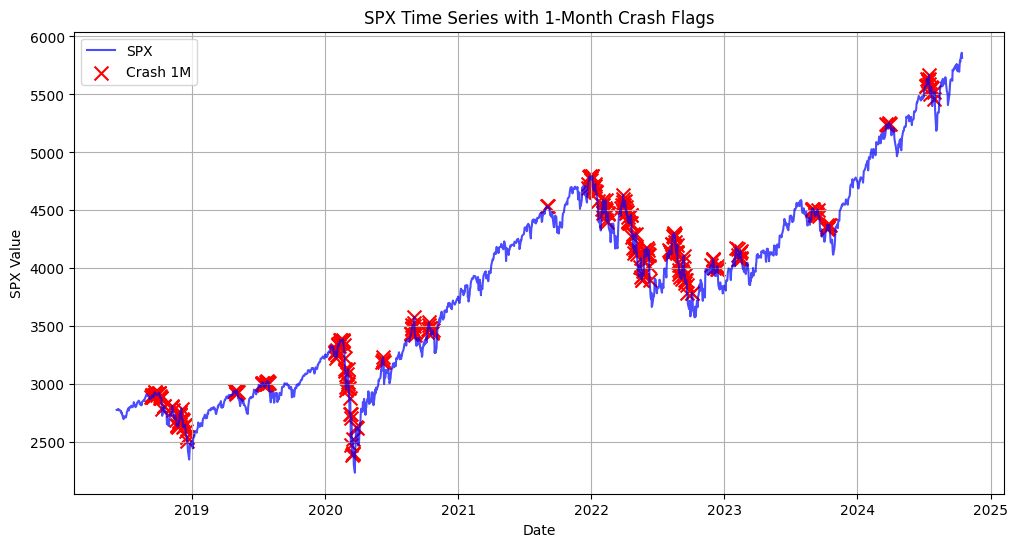

In [14]:
# Plot the SPX time series
plt.figure(figsize=(12, 6))
plt.plot(data.index, data['SPX'], label='SPX', color='blue', alpha=0.7)

# Highlight dates where crash_1M is 1
crash_dates = crash_dates_df[crash_dates_df['crash_flag'] == 1]
plt.scatter(crash_dates.index, data.loc[crash_dates.index, 'SPX'], color='red', label='Crash 1M', marker='x', s=100)

# Customize plot
plt.xlabel('Date')
plt.ylabel('SPX Value')
plt.title('SPX Time Series with 1-Month Crash Flags')
plt.legend()
plt.grid(True)
plt.show()

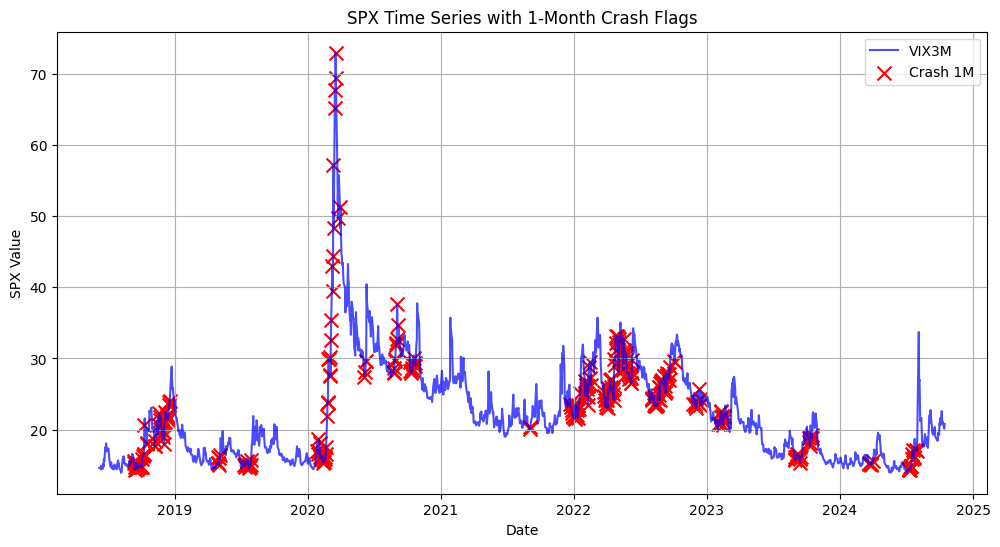

In [15]:
# Plot the SPX time series
plt.figure(figsize=(12, 6))
plt.plot(data.index, data['VIX3M'], label='VIX3M', color='blue', alpha=0.7)

# Highlight dates where crash_1M is 1
crash_dates = crash_dates_df[crash_dates_df['crash_flag'] == 1]
plt.scatter(crash_dates.index, data.loc[crash_dates.index, 'VIX3M'], color='red', label='Crash 1M', marker='x', s=100)

# Customize plot
plt.xlabel('Date')
plt.ylabel('SPX Value')
plt.title('SPX Time Series with 1-Month Crash Flags')
plt.legend()
plt.grid(True)
plt.show()

# 4 DATA FEATURISATION

In [16]:
data.dropna(inplace=True)

# 4.1 LOG TRANFORMATION

In [61]:
data.columns
# Step 1: Create pairwise differences
data['1M3M'] = data['VIX3M'] /data['VIX1M']
data['3M6M'] = data['VIX6M'] /data['VIX3M']
data['6M1Y'] = data['VIX1Y'] /data['VIX6M']
data['VIXSteep1M6M'] = data['3M6M'] /data['1M3M']
data['VIXSteep3M1Y'] = data['6M1Y'] /data['3M6M']

In [62]:
feature_columns=['SPX','VIX1M', 'VIX3M', 'VIX6M', 'VIX1Y', '1M3M', '3M6M', '6M1Y','VIXSteep1M6M', 'VIXSteep3M1Y']

In [63]:
log_transformed_data = pd.DataFrame(index=data.index)
log_transformed_data['Crash'] = data['crash_1M']
for col in feature_columns:
    # Apply log transformation
    log_transformed_data[f'log_{col}'] = np.log(data[col])
    
    # Calculate log variations (log differences)
    log_transformed_data[f'log_variation_{col}'] = log_transformed_data[f'log_{col}'].diff()
    # Calculate second-order log differences (second-order derivative of log variations)
    log_transformed_data[f'second_order_derivative_{col}'] = log_transformed_data[f'log_variation_{col}'].diff()

In [64]:
log_transformed_data.dropna(inplace=True)

In [65]:
log_transformed_data.columns

Index(['Crash', 'log_SPX', 'log_variation_SPX', 'second_order_derivative_SPX',
       'log_VIX1M', 'log_variation_VIX1M', 'second_order_derivative_VIX1M',
       'log_VIX3M', 'log_variation_VIX3M', 'second_order_derivative_VIX3M',
       'log_VIX6M', 'log_variation_VIX6M', 'second_order_derivative_VIX6M',
       'log_VIX1Y', 'log_variation_VIX1Y', 'second_order_derivative_VIX1Y',
       'log_1M3M', 'log_variation_1M3M', 'second_order_derivative_1M3M',
       'log_3M6M', 'log_variation_3M6M', 'second_order_derivative_3M6M',
       'log_6M1Y', 'log_variation_6M1Y', 'second_order_derivative_6M1Y',
       'log_VIXSteep1M6M', 'log_variation_VIXSteep1M6M',
       'second_order_derivative_VIXSteep1M6M', 'log_VIXSteep3M1Y',
       'log_variation_VIXSteep3M1Y', 'second_order_derivative_VIXSteep3M1Y'],
      dtype='object')

In [66]:
log_features=['log_SPX', 'log_variation_SPX', 'log_VIX1M',
       'log_variation_VIX1M', 'log_VIX3M', 'log_variation_VIX3M', 'log_VIX6M',
       'log_variation_VIX6M', 'log_VIX1Y', 'log_variation_VIX1Y', 'log_1M3M',
       'log_variation_1M3M', 'log_3M6M', 'log_variation_3M6M', 'log_6M1Y',
       'log_variation_6M1Y']

In [67]:
# Define the maximum number of lags to calculate changes from T-1
max_lag = 5  # Adjust as needed

# Calculate changes from T-1 backward for each variable
for lag in range(2, max_lag + 1):  # Start from T-2
    for col in log_features:
        # Calculate change from T-1 to T-lag
        log_transformed_data[f'{col}_Change_T1_to_T{lag}'] = log_transformed_data[col].shift(1) - log_transformed_data[col].shift(lag)


In [68]:
log_transformed_data.dropna(inplace=True)

In [69]:
log_transformed_data

,Crash,log_SPX,log_variation_SPX,second_order_derivative_SPX,log_VIX1M,log_variation_VIX1M,second_order_derivative_VIX1M,log_VIX3M,log_variation_VIX3M,second_order_derivative_VIX3M,...,log_VIX6M_Change_T1_to_T5,log_variation_VIX6M_Change_T1_to_T5,log_VIX1Y_Change_T1_to_T5,log_variation_VIX1Y_Change_T1_to_T5,log_1M3M_Change_T1_to_T5,log_variation_1M3M_Change_T1_to_T5,log_3M6M_Change_T1_to_T5,log_variation_3M6M_Change_T1_to_T5,log_6M1Y_Change_T1_to_T5,log_variation_6M1Y_Change_T1_to_T5
Date,,,,,,,,,,,,,,,,,,,,,
2018-06-19,0,7.923924,-0.004032,-0.001903,2.591516,0.081104,0.053931,2.719320,0.046551,0.042399,...,0.011070,-0.001260,0.021815,0.000495,-0.005134,-0.026577,0.018638,-0.002667,0.010745,0.001755
2018-06-20,0,7.925635,0.001711,0.005742,2.548664,-0.042853,-0.123957,2.693951,-0.025369,-0.071920,...,0.027613,0.016543,0.036593,0.014778,-0.014576,-0.009442,0.010996,-0.007643,0.008980,-0.001765
2018-06-21,0,7.919269,-0.006366,-0.008076,2.683758,0.135094,0.177947,2.764431,0.070479,0.095848,...,0.026374,-0.001239,0.026227,-0.010366,-0.027084,-0.012508,-0.000349,-0.011345,-0.000147,-0.009127
2018-06-22,0,7.921129,0.001860,0.008226,2.622492,-0.061265,-0.196359,2.740840,-0.023591,-0.094070,...,0.052518,0.026144,0.035838,0.009611,-0.104705,-0.077621,-0.043296,-0.042947,-0.016680,-0.016533
2018-06-25,0,7.907309,-0.013820,-0.015680,2.852439,0.229947,0.291212,2.863343,0.122503,0.146094,...,0.034268,-0.018250,0.028549,-0.007289,-0.044009,0.060696,-0.033803,0.009493,-0.005719,0.010961
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-10-08,0,8.657152,0.009643,0.019275,3.064325,-0.055393,-0.219680,3.068983,-0.048525,-0.138317,...,0.053078,0.006646,0.023551,0.002269,-0.083451,-0.016988,-0.025159,0.000174,-0.029527,-0.004378
2024-10-09,0,8.664240,0.007088,-0.002555,3.037833,-0.026492,0.028902,3.040228,-0.028755,0.019769,...,0.037672,-0.015406,0.016361,-0.007190,-0.080986,0.002465,-0.006505,0.018653,-0.021311,0.008217
2024-10-10,0,8.662168,-0.002072,-0.009160,3.041184,0.003350,0.029842,3.045474,0.005247,0.034002,...,-0.019488,-0.057160,-0.013654,-0.030015,-0.051750,0.029236,0.014365,0.020871,0.005835,0.027146


In [70]:
log_transformed_data.describe()

,Crash,log_SPX,log_variation_SPX,second_order_derivative_SPX,log_VIX1M,log_variation_VIX1M,second_order_derivative_VIX1M,log_VIX3M,log_variation_VIX3M,second_order_derivative_VIX3M,...,log_VIX6M_Change_T1_to_T5,log_variation_VIX6M_Change_T1_to_T5,log_VIX1Y_Change_T1_to_T5,log_variation_VIX1Y_Change_T1_to_T5,log_1M3M_Change_T1_to_T5,log_variation_1M3M_Change_T1_to_T5,log_3M6M_Change_T1_to_T5,log_variation_3M6M_Change_T1_to_T5,log_6M1Y_Change_T1_to_T5,log_variation_6M1Y_Change_T1_to_T5
count,1585.000000,1585.000000,1585.000000,1585.000000,1585.000000,1585.000000,1585.000000,1585.000000,1585.000000,1585.000000,...,1585.000000,1585.000000,1585.000000,1585.000000,1585.000000,1585.000000,1585.000000,1585.000000,1585.000000,1585.000000
mean,0.283281,8.236116,0.000472,0.000006,2.950048,0.000297,-0.000041,3.058447,0.000208,-0.000023,...,0.000765,-0.000043,0.000662,-0.000034,-0.000405,-0.000003,-0.000162,0.000004,-0.000103,0.000010
std,0.450734,0.218691,0.012742,0.019456,0.324210,0.077381,0.114800,0.280708,0.049651,0.072906,...,0.069438,0.051846,0.049016,0.036885,0.056887,0.046168,0.028583,0.022451,0.026275,0.022298
min,0.000000,7.713070,-0.127652,-0.216460,2.384165,-0.330681,-0.830848,2.634045,-0.230886,-0.598512,...,-0.384816,-0.368072,-0.339136,-0.268102,-0.299687,-0.207321,-0.173371,-0.106227,-0.173116,-0.131444
25%,0.000000,8.010751,-0.004736,-0.008472,2.689207,-0.043872,-0.055464,2.805177,-0.027148,-0.032165,...,-0.036566,-0.024078,-0.025293,-0.016366,-0.029201,-0.027548,-0.013762,-0.012128,-0.011514,-0.010269
50%,0.000000,8.279312,0.000866,-0.000479,2.917230,-0.008180,0.003134,3.033991,-0.004938,0.001861,...,-0.004966,0.001672,-0.002903,0.000575,0.003656,-0.001043,0.002801,-0.000836,0.002059,-0.000834
75%,1.000000,8.398243,0.006848,0.007594,3.149740,0.034602,0.059831,3.263084,0.020938,0.035133,...,0.031407,0.025318,0.022026,0.017892,0.031907,0.025522,0.016148,0.011425,0.013818,0.009918
max,1.000000,8.675879,0.089683,0.188753,4.415099,0.500166,0.623819,4.290185,0.367626,0.507062,...,0.478269,0.367043,0.327112,0.238711,0.230031,0.261585,0.119042,0.129953,0.157748,0.149541


In [71]:
drop_columns=['Crash']

In [72]:
X=log_transformed_data.drop(columns=drop_columns)

In [73]:
y=log_transformed_data['Crash']

In [74]:
100*y.value_counts().get(1, 0)/len(y)

28.32807570977918

# 4.2. STANDARD FEATURING NO LOG

In [17]:
data_featured= data.copy()

In [18]:
data_featured

,SPX,VIX1M,VIX3M,VIX6M,VIX1Y,SPX_Fwd_Return,Target,crash_1M
Date,,,,,,,,
2018-06-08,2779.03,12.18,14.60,16.13,17.23,0.001069,0,0
2018-06-11,2782.00,12.35,14.55,16.12,17.17,0.001743,0,0
2018-06-12,2786.85,12.34,14.59,16.17,17.23,-0.004026,0,0
2018-06-13,2775.63,12.94,14.92,16.43,17.44,0.002472,0,0
2018-06-14,2782.49,12.12,14.40,16.09,17.31,-0.001017,0,0
...,...,...,...,...,...,...,...,...
2024-10-08,5751.13,21.42,21.52,22.45,22.80,0.007113,0,0
2024-10-09,5792.04,20.86,20.91,21.85,22.55,-0.002070,0,0
2024-10-10,5780.05,20.93,21.02,21.96,22.54,0.006052,0,0


In [19]:
# Adding VIX term structure features
data_featured['Slope_1M_1Y'] = data_featured['VIX1M'] - data_featured['VIX1Y']  # Slope between VIX1M and VIX1Y
data_featured['Slope_1M_6M'] = data_featured['VIX1M'] - data_featured['VIX6M']  # Slope between VIX1M and VIX6M
data_featured['Slope_3M_1Y'] = data_featured['VIX3M'] - data_featured['VIX1Y']  # Slope between VIX3M and VIX1Y
data_featured['Spread_1M_3M'] = data_featured['VIX1M'] / data_featured['VIX3M']  # Spread ratio between VIX1M and VIX3M
data_featured['Spread_3M_6M'] = data_featured['VIX3M'] / data_featured['VIX6M']  # Spread ratio between VIX3M and VIX6M

# Rate of change in Slope_1M_1Y for volatility shifts
#data_featured['Slope_1M_1Y_Change'] = data_featured['Slope_1M_1Y'].pct_change()
# SPX percentage change to capture day-over-day changes
data_featured['SPX_Pct_Change'] = data_featured['SPX'].pct_change()

# Rolling windows for SPX changes to capture short-term trends (e.g., 5-day and 10-day moving averages)
data_featured['SPX_5D_Change'] = data_featured['SPX'].pct_change(periods=5)
data_featured['SPX_10D_Change'] = data_featured['SPX'].pct_change(periods=10)

# Volatility measure using the rolling standard deviation of SPX returns over a 10-day window
data_featured['SPX_10D_Volatility'] = data_featured['SPX_Pct_Change'].rolling(window=10).std()


# Drop rows where Slope_1M_1Y is 0
data_featured = data_featured[data_featured['Slope_1M_1Y'] != 0]

# Reset the index if needed, especially after dropping rows
#data_featured.reset_index(drop=True, inplace=True)

# Display the modified DataFrame
data_featured.head()


,SPX,VIX1M,VIX3M,VIX6M,VIX1Y,SPX_Fwd_Return,Target,crash_1M,Slope_1M_1Y,Slope_1M_6M,Slope_3M_1Y,Spread_1M_3M,Spread_3M_6M,SPX_Pct_Change,SPX_5D_Change,SPX_10D_Change,SPX_10D_Volatility
Date,,,,,,,,,,,,,,,,,
2018-06-08,2779.03,12.18,14.60,16.13,17.23,0.001069,0,0,-5.05,-3.95,-2.63,0.834247,0.905146,NaN,NaN,NaN,NaN
2018-06-11,2782.00,12.35,14.55,16.12,17.17,0.001743,0,0,-4.82,-3.77,-2.62,0.848797,0.902605,0.001069,NaN,NaN,NaN
2018-06-12,2786.85,12.34,14.59,16.17,17.23,-0.004026,0,0,-4.89,-3.83,-2.64,0.845785,0.902288,0.001743,NaN,NaN,NaN
2018-06-13,2775.63,12.94,14.92,16.43,17.44,0.002472,0,0,-4.50,-3.49,-2.52,0.867292,0.908095,-0.004026,NaN,NaN,NaN
2018-06-14,2782.49,12.12,14.40,16.09,17.31,-0.001017,0,0,-5.19,-3.97,-2.91,0.841667,0.894966,0.002472,NaN,NaN,NaN


In [20]:
print(data_featured.head())


                SPX  VIX1M  VIX3M  VIX6M  VIX1Y  SPX_Fwd_Return  Target  \
Date                                                                      
2018-06-08  2779.03  12.18  14.60  16.13  17.23        0.001069       0   
2018-06-11  2782.00  12.35  14.55  16.12  17.17        0.001743       0   
2018-06-12  2786.85  12.34  14.59  16.17  17.23       -0.004026       0   
2018-06-13  2775.63  12.94  14.92  16.43  17.44        0.002472       0   
2018-06-14  2782.49  12.12  14.40  16.09  17.31       -0.001017       0   

            crash_1M  Slope_1M_1Y  Slope_1M_6M  Slope_3M_1Y  Spread_1M_3M  \
Date                                                                        
2018-06-08         0        -5.05        -3.95        -2.63      0.834247   
2018-06-11         0        -4.82        -3.77        -2.62      0.848797   
2018-06-12         0        -4.89        -3.83        -2.64      0.845785   
2018-06-13         0        -4.50        -3.49        -2.52      0.867292   
2018-06-14  

In [21]:
data_featured.describe()

,SPX,VIX1M,VIX3M,VIX6M,VIX1Y,SPX_Fwd_Return,Target,crash_1M,Slope_1M_1Y,Slope_1M_6M,Slope_3M_1Y,Spread_1M_3M,Spread_3M_6M,SPX_Pct_Change,SPX_5D_Change,SPX_10D_Change,SPX_10D_Volatility
count,1591.000000,1591.000000,1591.000000,1591.000000,1591.000000,1591.000000,1591.000000,1591.000000,1591.000000,1591.000000,1591.000000,1591.000000,1591.000000,1590.000000,1586.000000,1581.000000,1581.000000
mean,3861.074733,20.207153,22.171559,23.433086,24.030968,0.000539,0.003143,0.282212,-3.823815,-3.225933,-1.859409,0.899991,0.938205,0.000546,0.002639,0.005268,0.010275
std,833.982669,7.902427,7.010267,6.183170,5.085466,0.012669,0.055989,0.450218,4.782375,3.369141,3.151455,0.075875,0.053598,0.012673,0.025723,0.035844,0.007685
min,2237.400000,10.850000,13.930000,15.410000,16.760000,-0.119841,0.000000,0.000000,-10.840000,-9.370000,-6.040000,0.753585,0.847130,-0.119841,-0.179666,-0.233863,0.002457
25%,3007.090000,14.660000,16.485000,18.005000,19.400000,-0.004719,0.000000,0.000000,-6.310000,-4.910000,-3.605000,0.846412,0.902139,-0.004695,-0.008844,-0.011097,0.005844
50%,3939.340000,18.410000,20.770000,22.790000,23.610000,0.000855,0.000000,0.000000,-4.800000,-3.680000,-2.390000,0.889955,0.931284,0.000861,0.005097,0.009667,0.008483
75%,4438.060000,23.310000,26.105000,27.665000,28.370000,0.006852,0.000000,1.000000,-2.540000,-2.245000,-1.175000,0.941805,0.962564,0.006855,0.016507,0.025837,0.012553
max,5859.850000,82.690000,72.980000,61.110000,45.860000,0.093828,1.000000,1.000000,41.220000,27.660000,27.120000,1.343719,1.252945,0.093828,0.173974,0.190525,0.074826


In [24]:
data_featured.dropna(inplace=True)

/var/folders/2g/jybkt1rx3x731rqm3lckb_j80000gn/T/ipykernel_9515/1408137342.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_featured.dropna(inplace=True)


In [25]:
data_featured.columns

Index(['SPX', 'VIX1M', 'VIX3M', 'VIX6M', 'VIX1Y', 'SPX_Fwd_Return', 'Target',
       'crash_1M', 'Slope_1M_1Y', 'Slope_1M_6M', 'Slope_3M_1Y', 'Spread_1M_3M',
       'Spread_3M_6M', 'SPX_Pct_Change', 'SPX_5D_Change', 'SPX_10D_Change',
       'SPX_10D_Volatility'],
      dtype='object')

In [26]:
feature_columns=['SPX', 'VIX1M', 'VIX3M', 'VIX6M', 'VIX1Y', 
       'crash_1M', 'Slope_1M_1Y', 'Slope_1M_6M', 'Slope_3M_1Y', 'Spread_1M_3M',
       'Spread_3M_6M', 'SPX_Pct_Change', 'SPX_5D_Change', 'SPX_10D_Change',
       'SPX_10D_Volatility']

In [27]:
# Caluclate first and second order derivatives features
for col in ['SPX']:    
    # Calculate log variations (log differences)
    data_featured[f'variation_{col}'] = data_featured[f'{col}'].diff()
    # Calculate second-order log differences (second-order derivative of log variations)
    data_featured[f'second_order_derivative_{col}'] = data_featured[f'variation_{col}'].diff()

/var/folders/2g/jybkt1rx3x731rqm3lckb_j80000gn/T/ipykernel_9515/2068648296.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_featured[f'variation_{col}'] = data_featured[f'{col}'].diff()
/var/folders/2g/jybkt1rx3x731rqm3lckb_j80000gn/T/ipykernel_9515/2068648296.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_featured[f'second_order_derivative_{col}'] = data_featured[f'variation_{col}'].diff()


In [28]:
data_featured.dropna(inplace=True)

/var/folders/2g/jybkt1rx3x731rqm3lckb_j80000gn/T/ipykernel_9515/1408137342.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_featured.dropna(inplace=True)


In [52]:
data_featured.columns

Index(['SPX', 'VIX1M', 'VIX3M', 'VIX6M', 'VIX1Y', 'SPX_Fwd_Return', 'Target',
       'crash_1M', 'Slope_1M_1Y', 'Slope_1M_6M', 'Slope_3M_1Y', 'Spread_1M_3M',
       'Spread_3M_6M', 'SPX_Pct_Change', 'SPX_5D_Change', 'SPX_10D_Change',
       'SPX_10D_Volatility', 'variation_SPX', 'second_order_derivative_SPX',
       'SPX_Change_T1_to_T2', 'VIX1M_Change_T1_to_T2', 'VIX3M_Change_T1_to_T2',
       'VIX6M_Change_T1_to_T2', 'VIX1Y_Change_T1_to_T2',
       'Slope_1M_1Y_Change_T1_to_T2', 'Slope_1M_6M_Change_T1_to_T2',
       'Slope_3M_1Y_Change_T1_to_T2', 'Spread_1M_3M_Change_T1_to_T2',
       'Spread_3M_6M_Change_T1_to_T2', 'SPX_Pct_Change_Change_T1_to_T2',
       'SPX_5D_Change_Change_T1_to_T2', 'SPX_10D_Change_Change_T1_to_T2',
       'SPX_10D_Volatility_Change_T1_to_T2', 'variation_SPX_Change_T1_to_T2',
       'second_order_derivative_SPX_Change_T1_to_T2', 'SPX_Change_T1_to_T3',
       'VIX1M_Change_T1_to_T3', 'VIX3M_Change_T1_to_T3',
       'VIX6M_Change_T1_to_T3', 'VIX1Y_Change_T1_to_T3

In [30]:
data_featured.describe()

,SPX,VIX1M,VIX3M,VIX6M,VIX1Y,SPX_Fwd_Return,Target,crash_1M,Slope_1M_1Y,Slope_1M_6M,Slope_3M_1Y,Spread_1M_3M,Spread_3M_6M,SPX_Pct_Change,SPX_5D_Change,SPX_10D_Change,SPX_10D_Volatility,variation_SPX,second_order_derivative_SPX
count,1579.000000,1579.000000,1579.000000,1579.000000,1579.000000,1579.000000,1579.000000,1579.000000,1579.000000,1579.000000,1579.000000,1579.000000,1579.000000,1579.000000,1579.000000,1579.000000,1579.000000,1579.000000,1579.000000
mean,3869.384972,20.260595,22.225548,23.484883,24.078980,0.000556,0.003167,0.284357,-3.818385,-3.224288,-1.853433,0.900204,0.938449,0.000564,0.002686,0.005295,0.010282,1.990361,0.052331
std,831.655921,7.907469,7.008940,6.177669,5.074541,0.012710,0.056201,0.451251,4.799274,3.381014,3.162413,0.076030,0.053702,0.012709,0.025767,0.035858,0.007686,44.307682,65.533852
min,2237.400000,10.850000,13.930000,15.410000,16.760000,-0.119841,0.000000,0.000000,-10.840000,-9.370000,-6.040000,0.753585,0.847130,-0.119841,-0.179666,-0.233863,0.002457,-324.890000,-555.270000
25%,3021.760000,14.740000,16.560000,18.045000,19.485000,-0.004730,0.000000,0.000000,-6.310000,-4.925000,-3.615000,0.846561,0.902532,-0.004719,-0.008695,-0.011080,0.005848,-17.365000,-32.170000
50%,3946.560000,18.490000,20.790000,22.880000,23.710000,0.000855,0.000000,0.000000,-4.800000,-3.670000,-2.370000,0.890542,0.931540,0.000866,0.005139,0.009783,0.008489,3.210000,-1.800000
75%,4442.360000,23.350000,26.190000,27.720000,28.410000,0.006875,0.000000,1.000000,-2.540000,-2.230000,-1.155000,0.942178,0.962783,0.006875,0.016538,0.025861,0.012558,25.225000,30.230000
max,5859.850000,82.690000,72.980000,61.110000,45.860000,0.093828,1.000000,1.000000,41.220000,27.660000,27.120000,1.343719,1.252945,0.093828,0.173974,0.190525,0.074826,230.380000,491.120000


In [31]:
all_features_columns=['SPX', 'VIX1M', 'VIX3M', 'VIX6M', 'VIX1Y','Slope_1M_1Y', 'Slope_1M_6M', 'Slope_3M_1Y', 'Spread_1M_3M',
       'Spread_3M_6M', 'SPX_Pct_Change', 'SPX_5D_Change', 'SPX_10D_Change',
       'SPX_10D_Volatility', 'variation_SPX', 'second_order_derivative_SPX']

In [32]:
# Define the maximum number of lags to calculate changes from T-1
max_lag = 5  # Adjust as needed

# Calculate changes from T-1 backward for each variable
for lag in range(2, max_lag + 1):  # Start from T-2
    for col in all_features_columns:
        # Calculate change from T-1 to T-lag
        data_featured[f'{col}_Change_T1_to_T{lag}'] = data_featured[col].shift(1) - data_featured[col].shift(lag)
data_featured.dropna(inplace=True)

/var/folders/2g/jybkt1rx3x731rqm3lckb_j80000gn/T/ipykernel_9515/2261316694.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_featured[f'{col}_Change_T1_to_T{lag}'] = data_featured[col].shift(1) - data_featured[col].shift(lag)
/var/folders/2g/jybkt1rx3x731rqm3lckb_j80000gn/T/ipykernel_9515/2261316694.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_featured[f'{col}_Change_T1_to_T{lag}'] = data_featured[col].shift(1) - data_featured[col].shift(lag)
/var/folders/2g/jybkt1rx3x731rqm3lckb_j80000gn

In [33]:
data_featured.columns

Index(['SPX', 'VIX1M', 'VIX3M', 'VIX6M', 'VIX1Y', 'SPX_Fwd_Return', 'Target',
       'crash_1M', 'Slope_1M_1Y', 'Slope_1M_6M', 'Slope_3M_1Y', 'Spread_1M_3M',
       'Spread_3M_6M', 'SPX_Pct_Change', 'SPX_5D_Change', 'SPX_10D_Change',
       'SPX_10D_Volatility', 'variation_SPX', 'second_order_derivative_SPX',
       'SPX_Change_T1_to_T2', 'VIX1M_Change_T1_to_T2', 'VIX3M_Change_T1_to_T2',
       'VIX6M_Change_T1_to_T2', 'VIX1Y_Change_T1_to_T2',
       'Slope_1M_1Y_Change_T1_to_T2', 'Slope_1M_6M_Change_T1_to_T2',
       'Slope_3M_1Y_Change_T1_to_T2', 'Spread_1M_3M_Change_T1_to_T2',
       'Spread_3M_6M_Change_T1_to_T2', 'SPX_Pct_Change_Change_T1_to_T2',
       'SPX_5D_Change_Change_T1_to_T2', 'SPX_10D_Change_Change_T1_to_T2',
       'SPX_10D_Volatility_Change_T1_to_T2', 'variation_SPX_Change_T1_to_T2',
       'second_order_derivative_SPX_Change_T1_to_T2', 'SPX_Change_T1_to_T3',
       'VIX1M_Change_T1_to_T3', 'VIX3M_Change_T1_to_T3',
       'VIX6M_Change_T1_to_T3', 'VIX1Y_Change_T1_to_T3

In [34]:
drop_columns= ['SPX_Fwd_Return', 'Target','crash_1M']

In [35]:
#X= data_featured.drop(columns=drop_columns)

In [53]:
#y=data_featured['crash_1M']
y=data_featured['Target']

In [54]:
# Check for infinite values in the DataFrame
inf_mask = X.isin([np.inf, -np.inf])

# Display columns that contain infinite values
columns_with_inf = X.columns[inf_mask.any(axis=0)]

# Display rows with infinite values and highlight the specific columns
rows_with_inf_and_columns = X.loc[:, columns_with_inf]

print("Columns with infinite values:", columns_with_inf)
print(rows_with_inf_and_columns)

Columns with infinite values: Index([], dtype='object')
Empty DataFrame
Columns: []
Index: [2018-07-03 00:00:00, 2018-07-05 00:00:00, 2018-07-06 00:00:00, 2018-07-09 00:00:00, 2018-07-10 00:00:00, 2018-07-11 00:00:00, 2018-07-12 00:00:00, 2018-07-13 00:00:00, 2018-07-16 00:00:00, 2018-07-17 00:00:00, 2018-07-18 00:00:00, 2018-07-19 00:00:00, 2018-07-20 00:00:00, 2018-07-23 00:00:00, 2018-07-24 00:00:00, 2018-07-25 00:00:00, 2018-07-26 00:00:00, 2018-07-27 00:00:00, 2018-07-30 00:00:00, 2018-07-31 00:00:00, 2018-08-01 00:00:00, 2018-08-02 00:00:00, 2018-08-03 00:00:00, 2018-08-06 00:00:00, 2018-08-07 00:00:00, 2018-08-08 00:00:00, 2018-08-09 00:00:00, 2018-08-10 00:00:00, 2018-08-13 00:00:00, 2018-08-14 00:00:00, 2018-08-15 00:00:00, 2018-08-16 00:00:00, 2018-08-17 00:00:00, 2018-08-20 00:00:00, 2018-08-21 00:00:00, 2018-08-22 00:00:00, 2018-08-23 00:00:00, 2018-08-24 00:00:00, 2018-08-27 00:00:00, 2018-08-28 00:00:00, 2018-08-29 00:00:00, 2018-08-30 00:00:00, 2018-08-31 00:00:00, 2018-

In [55]:
# Display only the rows and columns where infinite values are present
infinite_values = X[inf_mask]

# Show only the specific data points with infinite values
print(infinite_values.dropna(how='all', axis=1))  # Removes columns without any infinite values

Empty DataFrame
Columns: []
Index: [2018-07-03 00:00:00, 2018-07-05 00:00:00, 2018-07-06 00:00:00, 2018-07-09 00:00:00, 2018-07-10 00:00:00, 2018-07-11 00:00:00, 2018-07-12 00:00:00, 2018-07-13 00:00:00, 2018-07-16 00:00:00, 2018-07-17 00:00:00, 2018-07-18 00:00:00, 2018-07-19 00:00:00, 2018-07-20 00:00:00, 2018-07-23 00:00:00, 2018-07-24 00:00:00, 2018-07-25 00:00:00, 2018-07-26 00:00:00, 2018-07-27 00:00:00, 2018-07-30 00:00:00, 2018-07-31 00:00:00, 2018-08-01 00:00:00, 2018-08-02 00:00:00, 2018-08-03 00:00:00, 2018-08-06 00:00:00, 2018-08-07 00:00:00, 2018-08-08 00:00:00, 2018-08-09 00:00:00, 2018-08-10 00:00:00, 2018-08-13 00:00:00, 2018-08-14 00:00:00, 2018-08-15 00:00:00, 2018-08-16 00:00:00, 2018-08-17 00:00:00, 2018-08-20 00:00:00, 2018-08-21 00:00:00, 2018-08-22 00:00:00, 2018-08-23 00:00:00, 2018-08-24 00:00:00, 2018-08-27 00:00:00, 2018-08-28 00:00:00, 2018-08-29 00:00:00, 2018-08-30 00:00:00, 2018-08-31 00:00:00, 2018-09-04 00:00:00, 2018-09-05 00:00:00, 2018-09-06 00:00:00

In [56]:
inf_mask

,SPX,VIX1M,VIX3M,VIX6M,VIX1Y,Slope_1M_1Y,Slope_1M_6M,Slope_3M_1Y,Spread_1M_3M,Spread_3M_6M,...,Slope_1M_6M_Change_T1_to_T5,Slope_3M_1Y_Change_T1_to_T5,Spread_1M_3M_Change_T1_to_T5,Spread_3M_6M_Change_T1_to_T5,SPX_Pct_Change_Change_T1_to_T5,SPX_5D_Change_Change_T1_to_T5,SPX_10D_Change_Change_T1_to_T5,SPX_10D_Volatility_Change_T1_to_T5,variation_SPX_Change_T1_to_T5,second_order_derivative_SPX_Change_T1_to_T5
Date,,,,,,,,,,,,,,,,,,,,,
2018-07-03,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2018-07-05,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2018-07-06,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2018-07-09,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2018-07-10,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-10-08,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2024-10-09,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2024-10-10,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


# 5 IMPLEMENT MODEL

In [41]:
scaler=StandardScaler()

In [42]:
X_scaled=pd.DataFrame(scaler.fit_transform(X),columns=X.columns)

In [43]:
X_scaled

,SPX,VIX1M,VIX3M,VIX6M,VIX1Y,Slope_1M_1Y,Slope_1M_6M,Slope_3M_1Y,Spread_1M_3M,Spread_3M_6M,...,Slope_1M_6M_Change_T1_to_T5,Slope_3M_1Y_Change_T1_to_T5,Spread_1M_3M_Change_T1_to_T5,Spread_3M_6M_Change_T1_to_T5,SPX_Pct_Change_Change_T1_to_T5,SPX_5D_Change_Change_T1_to_T5,SPX_10D_Change_Change_T1_to_T5,SPX_10D_Volatility_Change_T1_to_T5,variation_SPX_Change_T1_to_T5,second_order_derivative_SPX_Change_T1_to_T5
0,-1.397101,-0.522159,-0.697514,-0.853293,-1.040234,0.237989,0.336630,0.121543,0.397300,0.247839,...,-0.256347,-0.053090,-0.438301,-0.182559,0.045849,0.529853,0.181427,0.340707,0.035771,-0.399094
1,-1.368926,-0.669990,-0.814451,-0.950409,-1.132901,0.092289,0.168193,0.011004,0.073429,-0.014828,...,-0.686077,-0.353610,-1.161645,-0.563342,0.196428,0.618923,0.292489,0.246533,0.155106,0.080326
2,-1.340968,-0.872150,-0.931388,-1.041050,-1.201908,-0.167890,-0.139131,-0.137435,-0.644117,-0.336212,...,-0.624687,-0.373645,-1.052117,-0.733666,0.130945,0.768348,0.391055,0.323047,0.104322,-0.034667
3,-1.311637,-0.958069,-1.051178,-1.167301,-1.320206,-0.184541,-0.109581,-0.213233,-0.613275,-0.475680,...,-0.870246,-0.507209,-1.642706,-0.981711,0.415597,0.869873,0.795047,0.397109,0.331356,0.153126
4,-1.299988,-0.964386,-1.073995,-1.196436,-1.353723,-0.159564,-0.071165,-0.210075,-0.535923,-0.470705,...,-0.629802,-0.553956,-1.254722,-1.099255,0.309522,0.613288,0.853472,0.467445,0.250542,-0.054966
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1569,2.262299,0.144972,-0.102844,-0.170244,-0.255526,0.508575,0.649865,0.181550,1.253134,0.375190,...,1.119810,0.775008,1.500047,0.881081,-0.014812,-0.220447,-0.533774,-0.300390,-0.023188,-0.300256
1570,2.311578,0.074215,-0.189834,-0.267360,-0.304817,0.444051,0.661685,0.067853,1.282790,0.345519,...,0.864019,0.374315,1.447472,0.224519,0.514136,0.285266,-0.408170,-0.029160,0.854132,0.592692
1571,2.297135,0.083060,-0.174148,-0.249555,-0.306789,0.460702,0.649865,0.105752,1.257935,0.349527,...,0.408710,-0.273471,0.939961,-0.500617,0.473375,0.663901,0.450166,0.834943,0.792971,-0.041681
1572,2.339271,0.023675,-0.209799,-0.281927,-0.320590,0.377445,0.570079,0.048903,1.117994,0.299469,...,0.695197,0.100508,1.223275,0.042376,-0.595805,0.349608,-0.079287,0.579053,-0.993586,-1.207976


In [45]:
# Define the split point for 80-20
split_point = int(len(data_featured) * 0.8)

# Split the data
X_train = X_scaled.iloc[:split_point]  # First 80% for training
X_test = X_scaled.iloc[split_point:]   # Last 20% for testing
y_train= y.iloc[:split_point]  # First 80% for training
y_test=y.iloc[split_point:]   # Last 20% for testing

# Display split sizes
print(f"Training set size: {X_train.shape[0]}")
print(f"Test set size: {X_test.shape[0]}")
y_benchmark = data['SPX'].iloc[split_point:]

Training set size: 1259
Test set size: 315


In [46]:
# Show the probability of occurrence
proba_train= round(100*y_train.value_counts().get(1, 0)/len(y_train), 2)
proba_test = round(100*y_test.value_counts().get(1, 0)/len(y_test), 2)
print(f"Number of crash occurrences across in train: {proba_train}%")
print(f"Number of crash occurrences across in test: {proba_test}%")

Number of crash occurrences across in train: 30.98%
Number of crash occurrences across in test: 18.73%


# 5.1 LASSO FOR FEATURE SELECTION

In [81]:
# Create a scorer for recall
recall_scorer = make_scorer(recall_score)

In [87]:
# Pipeline to standardize data and apply Logistic Regression with L1 regularization
lasso_logreg_pipeline = Pipeline([
    ('scaler', StandardScaler()),  # Standardize features
    ('lasso', LogisticRegression(penalty='l1', solver='liblinear', C=0.1, random_state=42))  # L1 regularization
])
lasso_logreg_pipeline.get_params()

{'memory': None,
 'steps': [('scaler', StandardScaler()),
  ('lasso',
   LogisticRegression(C=0.1, penalty='l1', random_state=42, solver='liblinear'))],
 'verbose': False,
 'scaler': StandardScaler(),
 'lasso': LogisticRegression(C=0.1, penalty='l1', random_state=42, solver='liblinear'),
 'scaler__copy': True,
 'scaler__with_mean': True,
 'scaler__with_std': True,
 'lasso__C': 0.1,
 'lasso__class_weight': None,
 'lasso__dual': False,
 'lasso__fit_intercept': True,
 'lasso__intercept_scaling': 1,
 'lasso__l1_ratio': None,
 'lasso__max_iter': 100,
 'lasso__multi_class': 'deprecated',
 'lasso__n_jobs': None,
 'lasso__penalty': 'l1',
 'lasso__random_state': 42,
 'lasso__solver': 'liblinear',
 'lasso__tol': 0.0001,
 'lasso__verbose': 0,
 'lasso__warm_start': False}

In [88]:


# Define the hyperparameters to search over (here, tuning the regularization parameter C)
param_grid = {
    'lasso__C': [1, 10,100]  # Adjust as needed
}

# Set up GridSearchCV to optimize for recall
grid_search = GridSearchCV(lasso_logreg_pipeline, param_grid, cv=5)
grid_search.fit(X_train, y_train)

# Best model and its recall
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)
best_recall = recall_score(y_test, y_pred)

print(f"Best Recall: {best_recall:.2f}")
print(f"Best Parameters: {grid_search.best_params_}")

Best Recall: 0.00
Best Parameters: {'lasso__C': 1}


Pipeline(steps=[('scaler', StandardScaler()),
                ('lasso',
                 LogisticRegression(C=0.1, penalty='l1', random_state=42,
                                    solver='liblinear'))])

In [89]:
# Get feature names and coefficients
feature_names = X.columns
coefficients = best_model.named_steps['lasso'].coef_[0]

# Select features with non-zero coefficients
selected_features = feature_names[coefficients != 0]
print("Selected features:", selected_features)

Selected features: Index(['log_SPX', 'log_VIX3M', 'log_variation_VIX1Y',
       'second_order_derivative_VIX1Y', 'log_3M6M', 'log_VIXSteep1M6M',
       'log_variation_VIXSteep1M6M', 'log_VIXSteep3M1Y',
       'log_variation_VIXSteep3M1Y', 'log_variation_SPX_Change_T1_to_T2',
       'log_variation_1M3M_Change_T1_to_T2', 'log_3M6M_Change_T1_to_T2',
       'log_variation_3M6M_Change_T1_to_T2',
       'log_variation_6M1Y_Change_T1_to_T2',
       'log_variation_VIX1Y_Change_T1_to_T3', 'log_1M3M_Change_T1_to_T3',
       'log_variation_6M1Y_Change_T1_to_T3',
       'log_variation_SPX_Change_T1_to_T4', 'log_1M3M_Change_T1_to_T4',
       'log_3M6M_Change_T1_to_T4', 'log_6M1Y_Change_T1_to_T4',
       'log_SPX_Change_T1_to_T5', 'log_variation_SPX_Change_T1_to_T5',
       'log_VIX6M_Change_T1_to_T5', 'log_variation_VIX1Y_Change_T1_to_T5',
       'log_1M3M_Change_T1_to_T5', 'log_variation_1M3M_Change_T1_to_T5',
       'log_3M6M_Change_T1_to_T5', 'log_variation_3M6M_Change_T1_to_T5',
       'log_6M1

In [90]:
# Make predictions
y_pred = best_model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Model accuracy:", accuracy)

Model accuracy: 0.6277602523659306


In [91]:
# Generate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

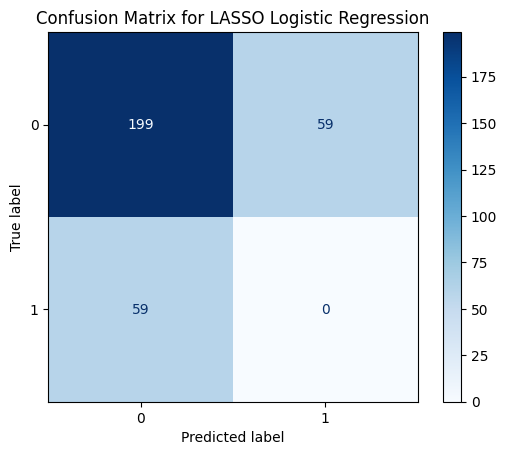

In [92]:
# Plot the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=lasso_logreg.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix for LASSO Logistic Regression")
plt.show()


# 5.2 XGB CLASSIFIER MODEL

In [75]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(sampling_strategy='minority', random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_train, y_train)

In [76]:
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV

# Define parameter grid
param_grid = {
    'n_estimators': [500],           # 2 values
    'max_depth': [3, 5],                  # 2 values
    'learning_rate': [0.01],         # 2 values
    'subsample': [0.8],                   # 1 value
    'colsample_bytree': [0.8],            # 1 value
    'gamma': [0.1],                       # 1 value
    'scale_pos_weight': [1, 5, 10]        # 3 values
}

# Initialize XGBClassifier
xgb_model = XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss')

# Set up GridSearchCV with recall as scoring to focus on crash events
grid_search = GridSearchCV(
    estimator=xgb_model,
    param_grid=param_grid,
    scoring='recall',         # Optimize for recall to capture crashes
    cv=5,                     # Cross-validation
    n_jobs=-1,
    verbose=1
)

# Fit grid search
grid_search.fit(X_train, y_train)

# Get the best estimator and parameters
best_model = grid_search.best_estimator_
print("Best Parameters:", grid_search.best_params_)
print("Best Score:", grid_search.best_score_)


Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best Parameters: {'colsample_bytree': 0.8, 'gamma': 0.1, 'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 500, 'scale_pos_weight': 10, 'subsample': 0.8}
Best Score: 0.6897435897435897


In [77]:
# Step 5: Make predictions and evaluate the model
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]  # Probability of crash (1)

# Print evaluation metrics
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Confusion Matrix:
 [[184  72]
 [ 47  12]]

Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.72      0.76       256
           1       0.14      0.20      0.17        59

    accuracy                           0.62       315
   macro avg       0.47      0.46      0.46       315
weighted avg       0.67      0.62      0.65       315



In [116]:
y_prob

array([0.25011677, 0.22360048, 0.49430645, 0.50782764, 0.4906537 ,
       0.36253452, 0.3955144 , 0.35922644, 0.3286705 , 0.37447253,
       0.352608  , 0.33177793, 0.32927752, 0.32643846, 0.32714146,
       0.23673865, 0.8492044 , 0.39107427, 0.38273335, 0.3951577 ,
       0.35967126, 0.22930214, 0.35447678, 0.50677174, 0.47362003,
       0.75227   , 0.37261146, 0.47814485, 0.4120933 , 0.21322046,
       0.35339087, 0.1870431 , 0.1630932 , 0.25127882, 0.13073638,
       0.12571806, 0.1545358 , 0.325091  , 0.34009677, 0.24059281,
       0.22981519, 0.2898478 , 0.34036493, 0.3295858 , 0.1878574 ,
       0.361155  , 0.23123369, 0.21334986, 0.3296345 , 0.85070205,
       0.792722  , 0.58650047, 0.90384823, 0.7935586 , 0.5524773 ,
       0.5925072 , 0.6325102 , 0.9144402 , 0.8565274 , 0.87646765,
       0.6068099 , 0.6059455 , 0.55347383, 0.39970922, 0.57184297,
       0.9183753 , 0.46451816, 0.52150226, 0.8844092 , 0.9047455 ,
       0.8688294 , 0.90830785, 0.89389545, 0.8966512 , 0.85848

In [78]:
threshold = 0.3  # Default is 0.5
y_pred_adjusted = (y_prob >= threshold).astype(int)
print("\nConfusion Matrix with Adjusted Threshold:\n", confusion_matrix(y_test, y_pred_adjusted))
print("\nClassification Report with Adjusted Threshold:\n", classification_report(y_test, y_pred_adjusted))


Confusion Matrix with Adjusted Threshold:
 [[149 107]
 [ 36  23]]

Classification Report with Adjusted Threshold:
               precision    recall  f1-score   support

           0       0.81      0.58      0.68       256
           1       0.18      0.39      0.24        59

    accuracy                           0.55       315
   macro avg       0.49      0.49      0.46       315
weighted avg       0.69      0.55      0.59       315



In [36]:


# Assuming `y_test` and `y_pred` are Series or arrays and `X_test` has a Date index
# Convert `y_test` and `y_pred` to DataFrames if necessary
y_test = pd.Series(y_test, index=X_test.index, name='Actual')
y_pred = pd.Series(y_pred, index=X_test.index, name='Predicted')
y_prod= pd.Series(y_prob, index=X_test.index, name='Proba')
# Combine into a single DataFrame for comparison
results = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred, 'Proba':y_prob})

# Identify mismatches where `Actual` is not equal to `Predicted`
mismatch_dates = results[results['Actual'] != results['Predicted']]
matching_dates = results[(results['Actual'] == 1) & (results['Predicted'] == 1)]
# Display the mismatched dates and their values
print("Dates with mismatches between Actual and Predicted:")
print(mismatch_dates)

print("Dates with matches between Actual and Predicted:")
print(matching_dates)



Dates with mismatches between Actual and Predicted:
      Actual  Predicted     Proba
1268     NaN          0  0.250117
1269     NaN          0  0.223600
1270     NaN          0  0.494306
1271     NaN          1  0.507828
1272     NaN          0  0.490654
...      ...        ...       ...
1580     NaN          1  0.806104
1581     NaN          1  0.807900
1582     NaN          1  0.818717
1583     NaN          1  0.824730
1584     NaN          1  0.838636

[317 rows x 3 columns]
Dates with matches between Actual and Predicted:
Empty DataFrame
Columns: [Actual, Predicted, Proba]
Index: []


In [37]:
# Initialize the `predicted_adjusted` column with 0s
results['proba_adjusted'] =df['Proba']

NameError: name 'df' is not defined

In [38]:
# Loop over each date in the DataFrame where Proba > 0.5
for current_date in results[results['Proba'] > 0.5].index:
    # Define the 1-month window (30 days)
    end_date = current_date + pd.DateOffset(days=30)
    
    # Set `predicted_adjusted` to 1 for each day in the window
    results.loc[current_date:end_date, 'proba_adjusted'] = results.loc[current_date:end_date, 'Proba']
results['proba_adjusted'].fillna(0, inplace=True)
print(results[['Proba', 'proba_adjusted']])

TypeError: unsupported operand type(s) for +: 'int' and 'DateOffset'

In [171]:
df=results.copy()

In [172]:
df[df['proba_adjusted']>0.5]

,Actual,Predicted,Proba,predicted_adjusted,proba_adjusted
Date,,,,,
2023-07-18,0,1,0.507828,0,0.507828
2023-08-04,0,1,0.849204,0,0.849204
2023-08-15,0,1,0.506772,0,0.506772
2023-08-17,0,1,0.752270,0,0.752270
2023-09-21,0,1,0.850702,0,0.850702
...,...,...,...,...,...
2024-10-08,0,1,0.806104,0,0.806104
2024-10-09,0,1,0.807900,0,0.807900
2024-10-10,0,1,0.818717,0,0.818717


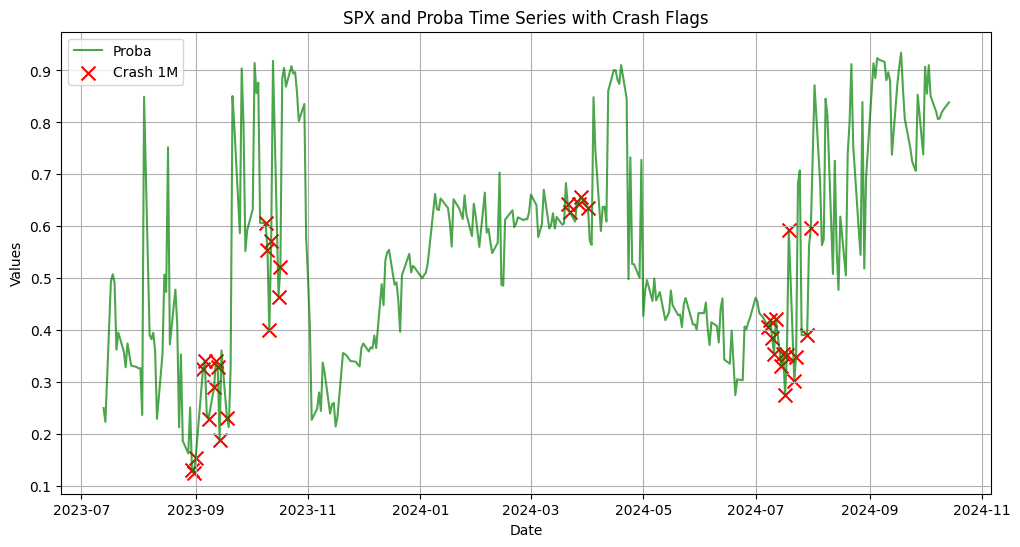

In [173]:
# Ensure both DataFrames have datetime indices
df.index = pd.to_datetime(df.index)
#data.index = pd.to_datetime(data.index)

# Plot SPX and Proba time series
plt.figure(figsize=(12, 6))
plt.plot(df.index, df['proba_adjusted'], label='Proba', color='green', alpha=0.7)
#plt.plot(data.index, data['SPX'], label='SPX', color='blue', alpha=0.7)

# Filter Proba values to match crash dates
crash_dates = crash_dates_df[crash_dates_df['crash_flag'] > 0.5]
proba_crash_values = df.loc[df.index.intersection(crash_dates.index), 'proba_adjusted']

# Plot the crash dates with matching Proba values
plt.scatter(proba_crash_values.index, proba_crash_values, color='red', label='Crash 1M', marker='x', s=100)

# Customize plot
plt.xlabel('Date')
plt.ylabel('Values')
plt.title('SPX and Proba Time Series with Crash Flags')
plt.legend()
plt.grid(True)
plt.show()


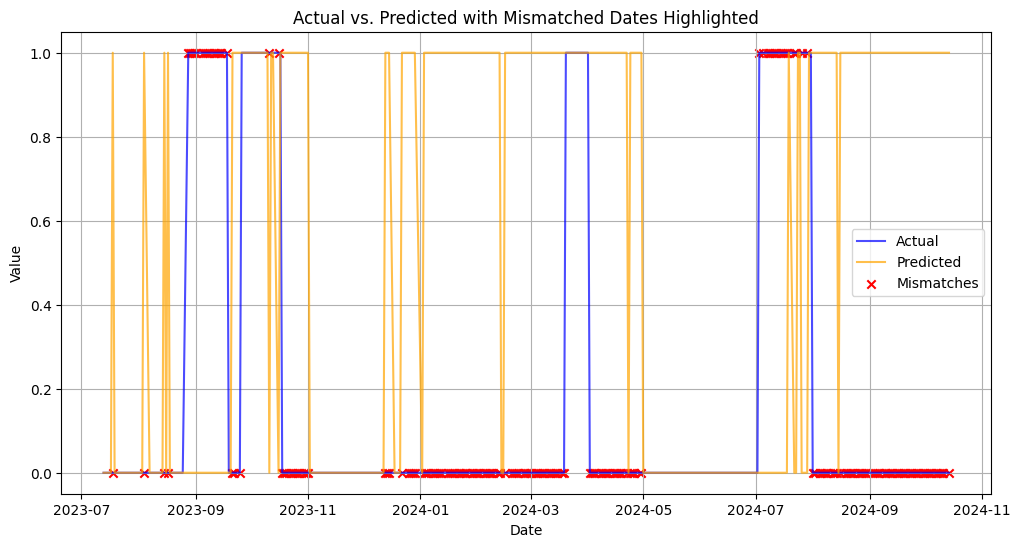

In [174]:
import matplotlib.pyplot as plt
# Plot the entire time series of Actual and Predicted values for context
plt.figure(figsize=(12, 6))
plt.plot(results.index, results['Actual'], label='Actual', color='blue', alpha=0.7)
plt.plot(results.index, results['Predicted'], label='Predicted', color='orange', alpha=0.7)

# Highlight mismatched dates
plt.scatter(mismatch_dates.index, mismatch_dates['Actual'], color='red', label='Mismatches', marker='x')

# Customize plot
plt.xlabel('Date')
plt.ylabel('Value')
plt.title('Actual vs. Predicted with Mismatched Dates Highlighted')
plt.legend()
plt.grid(True)
plt.show()

In [67]:
import pandas as pd

# Convert the index to DateTime if it's not already in that format
results.index = pd.to_datetime(results.index)

# Example time frame: 2 days before and after each prediction
time_frame = pd.Timedelta(days=30)

# Create a new column to flag true predictions
results['True_Flag'] = 0

# Iterate over rows where y_pred = 1
for index, row in results[results['Predicted'] == 1].iterrows():
    # Define the time window around the prediction date
    start_date = index 
    end_date = index + time_frame
    
    # Check if any actual `1` occurs within the time window
    if (results['Actual'].loc[start_date:end_date] == 1).any():
        results.at[index, 'True_Flag'] = 1  # Flag as true prediction if condition is met

# Display the results with the True_Flag column
print(results[['Actual', 'Predicted', 'True_Flag']])


            Actual  Predicted  True_Flag
Date                                    
2023-07-13       0          0          0
2023-07-14       0          0          0
2023-07-17       0          0          0
2023-07-18       0          0          0
2023-07-19       0          0          0
...            ...        ...        ...
2024-10-08       0          1          0
2024-10-09       0          1          0
2024-10-10       0          1          0
2024-10-11       0          1          0
2024-10-14       0          1          0

[317 rows x 3 columns]


In [68]:
# Identify mismatches where `Actual` is not equal to `Predicted`
mismatch_dates = results[results['Actual'] != results['True_Flag']]
matching_dates = results[(results['Actual'] == 1) & (results['True_Flag'] == 1)]
# Display the mismatched dates and their values
print("Dates with mismatches between Actual and Predicted:")
print(mismatch_dates)

print("Dates with matches between Actual and Predicted:")
print(matching_dates)


Dates with mismatches between Actual and Predicted:
            Actual  Predicted     Proba  True_Flag
Date                                              
2023-08-04       0          1  0.909578          1
2023-08-17       0          1  0.906695          1
2023-08-18       0          1  0.716988          1
2023-08-21       0          1  0.646898          1
2023-08-22       0          1  0.598133          1
...            ...        ...       ...        ...
2024-07-18       1          0  0.382690          0
2024-07-22       1          0  0.485382          0
2024-07-23       1          0  0.417846          0
2024-08-27       1          0  0.453867          0
2024-08-29       1          0  0.405437          0

[71 rows x 4 columns]
Dates with matches between Actual and Predicted:
            Actual  Predicted     Proba  True_Flag
Date                                              
2023-09-21       1          1  0.939378          1
2023-09-22       1          1  0.937330          1
2023-09-2

In [39]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Calculate probabilities for the positive class (crash = 1)
#y_prob = logreg.predict_proba(X_test)[:, 1]

# Calculate the ROC curve points
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calculate the AUC score
auc_score = roc_auc_score(y_test, y_prob)
print(f"AUC Score: {auc_score:.4f}")

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', label=f'ROC Curve (AUC = {auc_score:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')  # Dashed line for random guessing
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()


/Users/alamazou/.pyenv/versions/d1quantenv/lib/python3.10/site-packages/sklearn/utils/_array_api.py:390: RuntimeWarning: invalid value encountered in cast
  return x.astype(dtype, copy=copy, casting=casting)


ValueError: Input y_true contains NaN.

In [165]:
# Calculate True Positives and False Positives
true_positives = results[(results['Predicted'] == 1) & (results['True_Flag'] == 1)].shape[0]
false_positives = results[(results['Predicted'] == 1) & (results['True_Flag'] == 0)].shape[0]

# Calculate precision
precision = true_positives / (true_positives + false_positives) if (true_positives + false_positives) > 0 else 0

# Display the precision
print(f"Adjusted Precision: {precision:.4f}")


Adjusted Precision: 0.2381


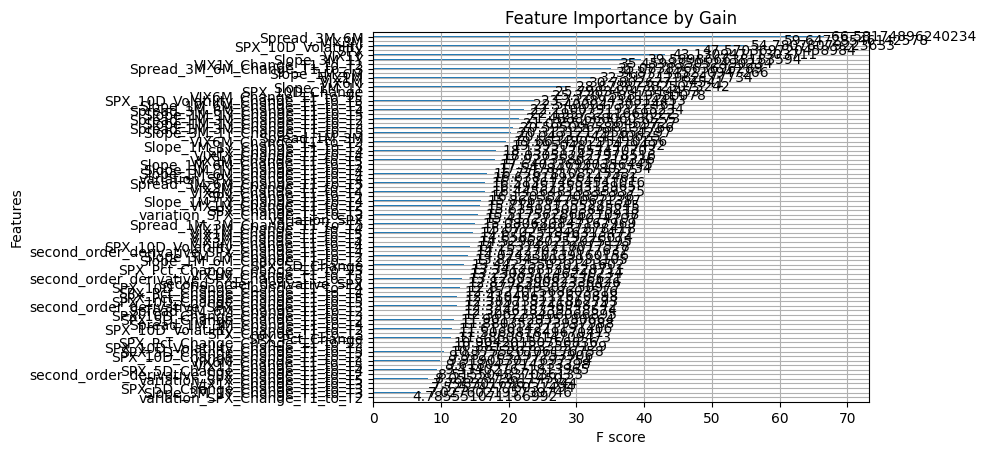

In [51]:
from xgboost import plot_importance
import matplotlib.pyplot as plt

# Use 'weight', 'gain', or 'cover' to see different aspects of feature importance
plot_importance(best_model, importance_type='gain')  # Gain is often more informative
plt.title("Feature Importance by Gain")
plt.show()

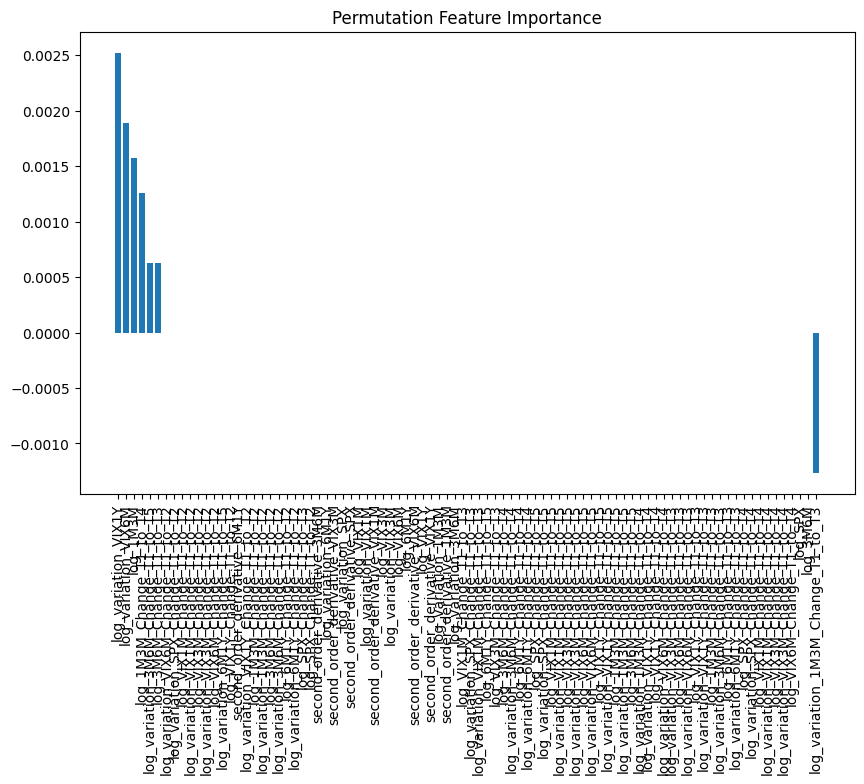

In [142]:
from sklearn.inspection import permutation_importance

# Calculate permutation importance
result = permutation_importance(model, X_test, y_test, n_repeats=10, random_state=42)
sorted_indices = result.importances_mean.argsort()[::-1]

# Plot permutation importance
plt.figure(figsize=(10, 6))
plt.bar(range(len(X_test.columns)), result.importances_mean[sorted_indices], tick_label=X_test.columns[sorted_indices])
plt.xticks(rotation=90)
plt.title("Permutation Feature Importance")
plt.show()


In [26]:
import pandas as pd
from xgboost import XGBClassifier

# Assuming `model` is your trained XGBClassifier and `X_train` is the training DataFrame

# Get feature importance scores based on 'gain'
feature_importance = model.get_booster().get_score(importance_type='gain')

# Convert to a DataFrame for easier manipulation
importance_df = pd.DataFrame(
    list(feature_importance.items()), columns=['Feature', 'Importance']
)

# Sort features by importance in descending order
importance_df = importance_df.sort_values(by='Importance', ascending=False)

# Calculate cumulative importance
importance_df['Cumulative Importance'] = importance_df['Importance'].cumsum() / importance_df['Importance'].sum()

# Filter features that contribute up to 90% of the importance
top_features = importance_df[importance_df['Cumulative Importance'] <= 0.8]['Feature'].tolist()

# Display the selected features
print("Top features explaining 90% of the model:", top_features)


Top features explaining 90% of the model: ['6M1Y', '3M6M_Change_T1_to_T4', 'VIX6M_Change_T1_to_T2', 'VIX1M', 'SPX_Change_T1_to_T4', 'SPX_Change_T1_to_T5', 'VIX3M_Change_T1_to_T2', 'VIX6M', '3M6M', 'VIX6M_Change_T1_to_T5', '1M3M_Change_T1_to_T5', '1M3M', '3M6M_Change_T1_to_T2', 'SPX_Change_T1_to_T2', '6M1Y_Change_T1_to_T4', 'SPX_Change_T1_to_T3']


In [217]:
import numpy as np

Final Benchmark Return: 1.2893663013046082
Final Strategy Return: 1.2795793225393712


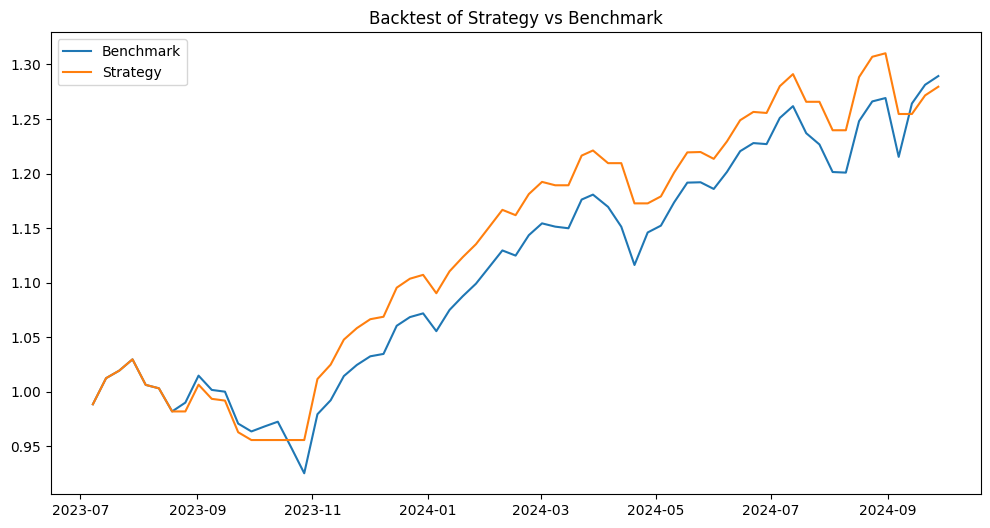

In [218]:

# Assume `X_test` is your test set features, `y_test` is the actual target values, 
# and `y_pred` is the predicted target values from the model.

# Get model predictions (assuming `model` is trained)
y_pred = model.predict(X_test)

# Create a DataFrame for backtesting
backtest_data = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred,
    'Benchmark': y_benchmark  # Replace 'y' with the actual column name for the benchmark series
})

# Strategy - Sell when crash is predicted (Predicted == 1), otherwise hold
backtest_data['Position'] = np.where(backtest_data['Predicted'] == 1, 0, 1)

# Calculate Returns
backtest_data['Benchmark_Returns'] = backtest_data['Benchmark'].pct_change()  # Daily returns of benchmark
backtest_data['Strategy_Returns'] = backtest_data['Benchmark_Returns'] * backtest_data['Position'].shift(1)

# Calculate Cumulative Returns for Benchmark and Strategy
backtest_data['Benchmark_Cumulative'] = (1 + backtest_data['Benchmark_Returns']).cumprod()
backtest_data['Strategy_Cumulative'] = (1 + backtest_data['Strategy_Returns']).cumprod()

# Display results
print("Final Benchmark Return:", backtest_data['Benchmark_Cumulative'].iloc[-1])
print("Final Strategy Return:", backtest_data['Strategy_Cumulative'].iloc[-1])



plt.figure(figsize=(12, 6))
plt.plot(backtest_data['Benchmark_Cumulative'], label='Benchmark')
plt.plot(backtest_data['Strategy_Cumulative'], label='Strategy')
plt.legend()
plt.title("Backtest of Strategy vs Benchmark")
plt.show()


In [223]:


# Calculate benchmark returns if not already calculated
backtest_data['Benchmark_Returns'] = backtest_data['Benchmark'].pct_change()

# Calculate Volatility (Standard Deviation of Returns)
benchmark_volatility = backtest_data['Benchmark_Returns'].std() * np.sqrt(52)  # Annualized volatility
strategy_volatility = backtest_data['Strategy_Returns'].std() * np.sqrt(52)    # Annualized volatility

# Display results
print("Benchmark Volatility (Annualized):", benchmark_volatility)
print("Strategy Volatility (Annualized):", strategy_volatility)


Benchmark Volatility (Annualized): 0.12965633005796817
Strategy Volatility (Annualized): 0.11682605228420234


In [225]:
backtest_data

,Actual,Predicted,Benchmark,Position,Benchmark_Returns,Strategy_Returns,Benchmark_Cumulative,Strategy_Cumulative
Date,,,,,,,,
2023-06-30 16:00:00,0,0,4450.38,1,NaN,NaN,NaN,NaN
2023-07-07 16:00:00,1,0,4398.95,1,-0.011556,-0.011556,0.988444,0.988444
2023-07-14 16:00:00,0,0,4505.42,1,0.024204,0.024204,1.012367,1.012367
2023-07-21 16:00:00,0,0,4536.34,1,0.006863,0.006863,1.019315,1.019315
2023-07-28 16:00:00,0,0,4582.23,1,0.010116,0.010116,1.029627,1.029627
...,...,...,...,...,...,...,...,...
2024-08-30 16:00:00,0,0,5648.40,1,0.002447,0.002447,1.269195,1.310238
2024-09-06 16:00:00,1,1,5408.42,0,-0.042486,-0.042486,1.215272,1.254571
2024-09-13 16:00:00,0,0,5626.02,1,0.040234,0.000000,1.264166,1.254571


In [221]:
from sklearn.ensemble import IsolationForest

# Train Isolation Forest on normal data only if possible
model = IsolationForest(contamination=0.1, random_state=42)  # Adjust contamination based on crash frequency
model.fit(X_resampled)

# Predict anomalies in the test set
y_pred = model.predict(X_test)
y_pred = [1 if x == -1 else 0 for x in y_pred]  # Convert -1 (anomaly) to 1 (crash), and 1 (normal) to 0

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))


Confusion Matrix:
 [[48  5]
 [13  0]]
Classification Report:
               precision    recall  f1-score   support

           0       0.79      0.91      0.84        53
           1       0.00      0.00      0.00        13

    accuracy                           0.73        66
   macro avg       0.39      0.45      0.42        66
weighted avg       0.63      0.73      0.68        66



In [166]:
# Initialize the Logistic Regression model
logreg = LogisticRegression(random_state=42, class_weight='balanced', max_iter=1000)

# Fit the model on the training data
logreg.fit(X_resampled, y_resampled)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [167]:
# Predict class labels
y_pred = logreg.predict(X_test)

# Predict probabilities
y_prob = logreg.predict_proba(X_test)[:, 1]  # Probability of the crash class (1)

In [169]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, recall_score
# Print classification report
print("Classification Report:\n", classification_report(y_test, y_pred))

# Confusion matrix
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

# Recall score
recall = recall_score(y_test, y_pred)
print(f"Recall Score: {recall:.4f}")

Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.70      0.78       280
           1       0.11      0.27      0.15        37

    accuracy                           0.65       317
   macro avg       0.49      0.49      0.47       317
weighted avg       0.79      0.65      0.71       317

Confusion Matrix:
 [[196  84]
 [ 27  10]]
Recall Score: 0.2703
